In [ ]:
sql table connect 

In [2]:
import mysql.connector

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="pRaN@Li005",
    database="customer"
)

print("Database connected successfully!")

Database connected successfully!


In [3]:
cursor = connection.cursor()

query = "SELECT * FROM cust"

cursor.execute(query)

data = cursor.fetchall()

print(data)

[(101, 'Amit Sharma', 'Pune', 'Maharashtra', datetime.date(2025, 1, 15)), (102, 'Priya Patel', 'Mumbai', 'Maharashtra', datetime.date(2025, 2, 20)), (103, 'Rahul Singh', 'Delhi', 'Delhi', datetime.date(2025, 3, 10)), (104, 'Sneha Joshi', 'Pune', 'Maharashtra', datetime.date(2025, 3, 25)), (105, 'Vishal Kumar', 'Bangalore', 'Karnataka', datetime.date(2025, 4, 12)), (106, 'Neha Deshmukh', 'Nashik', 'Maharashtra', datetime.date(2025, 5, 5)), (107, 'Rohit Verma', 'Mumbai', 'Maharashtra', datetime.date(2025, 6, 18)), (108, 'Pooja Patil', 'Kolhapur', 'Maharashtra', datetime.date(2025, 7, 22)), (109, 'Karan Mehta', 'Ahmedabad', 'Gujarat', datetime.date(2025, 8, 14)), (110, 'Anjali Shah', 'Surat', 'Gujarat', datetime.date(2025, 9, 30))]


In [4]:
cursor = connection.cursor()

query = "select category,max(o.quantity * o.price) as highest_revenue from cust c join orders o on c.customer_id=o.customer_id group by category"

cursor.execute(query)

data = cursor.fetchall()

print(data)

[('Electronics', Decimal('55000.00')), ('Furniture', Decimal('25000.00')), ('Fashion', Decimal('9000.00')), ('Accessories', Decimal('7500.00'))]


In [5]:
import pandas as pd

In [6]:
query='select * from orders'
df_orders=pd.read_sql(query,connection)
print(df_orders)

    order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1005          104  2025-03-28           Keyboard  Electronics   
5       1006          105  2025-04-15      Running Shoes      Fashion   
6       1007          102  2025-04-20           Backpack      Fashion   
7       1008          106  2025-05-10            Monitor  Electronics   
8       1009          107  2025-05-22            T-Shirt      Fashion   
9       1010          101  2025-06-05              Mouse  Electronics   
10      1011          108  2025-06-15               Sofa    Furniture   
11      1012          109  2025-07-05              Watch  Accessories   
12      1013          102  2025-07-18             T

C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\4164427481.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_orders=pd.read_sql(query,connection)


In [7]:
query='select * from cust'
df_cust=pd.read_sql(query,connection)
print(df_cust)

   customer_id  customer_name       city        state signup_date
0          101    Amit Sharma       Pune  Maharashtra  2025-01-15
1          102    Priya Patel     Mumbai  Maharashtra  2025-02-20
2          103    Rahul Singh      Delhi        Delhi  2025-03-10
3          104    Sneha Joshi       Pune  Maharashtra  2025-03-25
4          105   Vishal Kumar  Bangalore    Karnataka  2025-04-12
5          106  Neha Deshmukh     Nashik  Maharashtra  2025-05-05
6          107    Rohit Verma     Mumbai  Maharashtra  2025-06-18
7          108    Pooja Patil   Kolhapur  Maharashtra  2025-07-22
8          109    Karan Mehta  Ahmedabad      Gujarat  2025-08-14
9          110    Anjali Shah      Surat      Gujarat  2025-09-30


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\826947181.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cust=pd.read_sql(query,connection)


In [9]:
#data cleaning 
print(df_cust.shape)
print(df_orders.shape)

(10, 5)
(30, 9)


In [10]:
#understand data
print(df_cust.head(1))

   customer_id customer_name  city        state signup_date
0          101   Amit Sharma  Pune  Maharashtra  2025-01-15


In [53]:
print(df_orders.head(2))

   order_id  customer_id  order_date     product     category  quantity  \
0      1001          101  2025-01-20      Laptop  Electronics         1   
1      1002          102  2025-02-25  Smartphone  Electronics         1   

     price payment_method order_status  
0  55000.0            UPI    Delivered  
1  30000.0    Credit Card    Delivered  


In [11]:
print(df_cust.tail(1))

   customer_id customer_name   city    state signup_date
9          110   Anjali Shah  Surat  Gujarat  2025-09-30


In [12]:
print(df_orders.tail(3))

    order_id  customer_id  order_date       product     category  quantity  \
27      1028          109  2025-12-10  Gaming Mouse  Electronics         1   
28      1029          110  2025-12-18         Kurti      Fashion         2   
29      1030          101  2025-12-25    Power Bank  Electronics         2   

     price payment_method order_status  
27  2500.0            UPI    Delivered  
28  1600.0    Credit Card    Delivered  
29  1800.0            UPI    Delivered  


In [56]:
print(df_orders.describe())

          order_id  customer_id   quantity         price
count    30.000000    30.000000  30.000000     30.000000
mean   1015.500000   104.733333   1.400000   9970.000000
std       8.803408     2.899861   0.723974  12234.861159
min    1001.000000   101.000000   1.000000    500.000000
25%    1008.250000   102.000000   1.000000   1900.000000
50%    1015.500000   104.500000   1.000000   4350.000000
75%    1022.750000   107.000000   2.000000  12375.000000
max    1030.000000   110.000000   4.000000  55000.000000


In [57]:
print(df_orders.describe)

<bound method NDFrame.describe of     order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1005          104  2025-03-28           Keyboard  Electronics   
5       1006          105  2025-04-15      Running Shoes      Fashion   
6       1007          102  2025-04-20           Backpack      Fashion   
7       1008          106  2025-05-10            Monitor  Electronics   
8       1009          107  2025-05-22            T-Shirt      Fashion   
9       1010          101  2025-06-05              Mouse  Electronics   
10      1011          108  2025-06-15               Sofa    Furniture   
11      1012          109  2025-07-05              Watch  Accessories   
12      1013     

In [59]:
print(df_cust.size)
print(df_orders.size)

50
270


In [61]:
print(df_cust.isnull())


   customer_id  customer_name   city  state  signup_date
0        False          False  False  False        False
1        False          False  False  False        False
2        False          False  False  False        False
3        False          False  False  False        False
4        False          False  False  False        False
5        False          False  False  False        False
6        False          False  False  False        False
7        False          False  False  False        False
8        False          False  False  False        False
9        False          False  False  False        False


In [62]:
print(df_orders.isnull().sum())

order_id          0
customer_id       0
order_date        0
product           0
category          0
quantity          0
price             0
payment_method    0
order_status      0
dtype: int64


In [63]:
print(df_orders.dropna())

    order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1005          104  2025-03-28           Keyboard  Electronics   
5       1006          105  2025-04-15      Running Shoes      Fashion   
6       1007          102  2025-04-20           Backpack      Fashion   
7       1008          106  2025-05-10            Monitor  Electronics   
8       1009          107  2025-05-22            T-Shirt      Fashion   
9       1010          101  2025-06-05              Mouse  Electronics   
10      1011          108  2025-06-15               Sofa    Furniture   
11      1012          109  2025-07-05              Watch  Accessories   
12      1013          102  2025-07-18             T

In [64]:
print(df_orders.fillna('as'))

    order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1005          104  2025-03-28           Keyboard  Electronics   
5       1006          105  2025-04-15      Running Shoes      Fashion   
6       1007          102  2025-04-20           Backpack      Fashion   
7       1008          106  2025-05-10            Monitor  Electronics   
8       1009          107  2025-05-22            T-Shirt      Fashion   
9       1010          101  2025-06-05              Mouse  Electronics   
10      1011          108  2025-06-15               Sofa    Furniture   
11      1012          109  2025-07-05              Watch  Accessories   
12      1013          102  2025-07-18             T

In [13]:
query = """
SELECT *
FROM orders
WHERE order_status = 'Delivered'
"""

df = pd.read_sql(query, connection)

print(df)

    order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1005          104  2025-03-28           Keyboard  Electronics   
5       1006          105  2025-04-15      Running Shoes      Fashion   
6       1007          102  2025-04-20           Backpack      Fashion   
7       1008          106  2025-05-10            Monitor  Electronics   
8       1009          107  2025-05-22            T-Shirt      Fashion   
9       1010          101  2025-06-05              Mouse  Electronics   
10      1011          108  2025-06-15               Sofa    Furniture   
11      1012          109  2025-07-05              Watch  Accessories   
12      1013          102  2025-07-18             T

C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\3669685640.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


In [14]:
#Find the second-highest order value.
query="select category,max(o.quantity * o.price) as highest_revenue from cust c join orders o on c.customer_id=o.customer_id group by category"
df=pd.read_sql(query,connection)
print(df)

      category  highest_revenue
0  Electronics          55000.0
1    Furniture          25000.0
2      Fashion           9000.0
3  Accessories           7500.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\1423347930.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


In [15]:
query="select * from orders where price>=2000"
df=pd.read_sql(query,connection)
print(df)

    order_id  customer_id  order_date            product     category  \
0       1001          101  2025-01-20             Laptop  Electronics   
1       1002          102  2025-02-25         Smartphone  Electronics   
2       1003          103  2025-03-15         Headphones  Electronics   
3       1004          101  2025-03-20       Office Chair    Furniture   
4       1006          105  2025-04-15      Running Shoes      Fashion   
5       1007          102  2025-04-20           Backpack      Fashion   
6       1008          106  2025-05-10            Monitor  Electronics   
7       1011          108  2025-06-15               Sofa    Furniture   
8       1012          109  2025-07-05              Watch  Accessories   
9       1013          102  2025-07-18             Tablet  Electronics   
10      1015          104  2025-08-02            Printer  Electronics   
11      1016          105  2025-08-12             Jacket      Fashion   
12      1017          106  2025-08-20       Dining 

C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\629335192.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


In [29]:
import pandas as pd

In [16]:
import matplotlib.pyplot as plt

In [17]:
query = """
SELECT 
    product,
    SUM(quantity) AS quantity_sold
FROM orders
WHERE order_status = 'Delivered'
GROUP BY product
ORDER BY quantity_sold DESC
"""

df = pd.read_sql(query, connection)

print(df)
print(df.columns)

              product  quantity_sold
0           USB Cable            4.0
1             T-Shirt            3.0
2          Headphones            2.0
3       Running Shoes            2.0
4               Mouse            2.0
5               Kurti            2.0
6          Power Bank            2.0
7              Laptop            1.0
8          Smartphone            1.0
9        Office Chair            1.0
10           Keyboard            1.0
11           Backpack            1.0
12            Monitor            1.0
13               Sofa            1.0
14              Watch            1.0
15             Tablet            1.0
16            Printer            1.0
17             Jacket            1.0
18       Dining Table            1.0
19         Smartwatch            1.0
20            Handbag            1.0
21         Laptop Bag            1.0
22  Bluetooth Speaker            1.0
23       Formal Shoes            1.0
24       Mobile Phone            1.0
25          Bookshelf            1.0
2

C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\3772448635.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


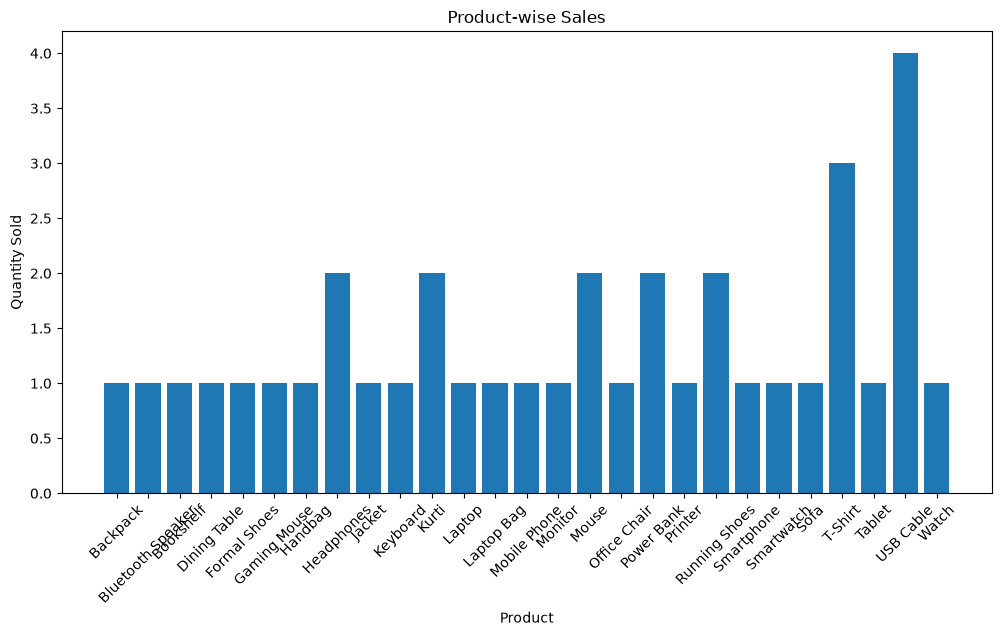

In [18]:
plt.figure(figsize=(12, 6))
product_sales = df.groupby("product")["quantity_sold"].sum()

plt.bar(product_sales.index, product_sales.values)

plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.title("Product-wise Sales")

plt.xticks(rotation=45)

plt.show()

In [19]:
print(df.columns)

Index(['product', 'quantity_sold'], dtype='str')


In [20]:
#Category-wise revenue
query="select category,sum(quantity*price) as revenue_category from orders group by category order by  revenue_category desc"
df=pd.read_sql(query,connection)
print(df)

      category  revenue_category
0  Electronics          186300.0
1    Furniture           77000.0
2      Fashion           33900.0
3  Accessories           20400.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\3691082913.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


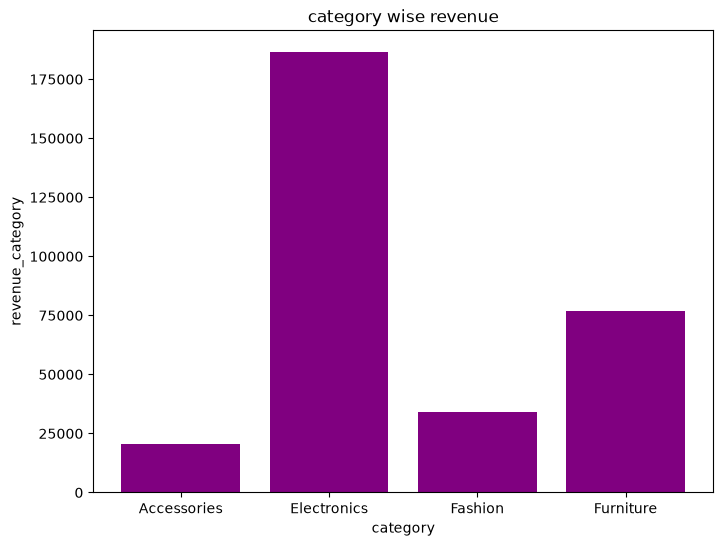

In [21]:
#motplotlib chart
plt.figure(figsize=(8, 6))
category_revenue=df.groupby('category')['revenue_category'].sum()

plt.bar(category_revenue.index,category_revenue.values,color='purple')

plt.xlabel('category')

plt.ylabel('revenue_category')

plt.title('category wise revenue')

plt.show()


In [ ]:
#line chart

In [22]:
query="select month(signup_date) as month_number ,sum(quantity * price) as highest_sales from orders o join cust c on o.customer_id=c.customer_id group by month(signup_date)order by  highest_sales desc limit 2 "

df=pd.read_sql(query,connection)
print(df)

   month_number  highest_sales
0             1        71500.0
1             5        68000.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\1076683415.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


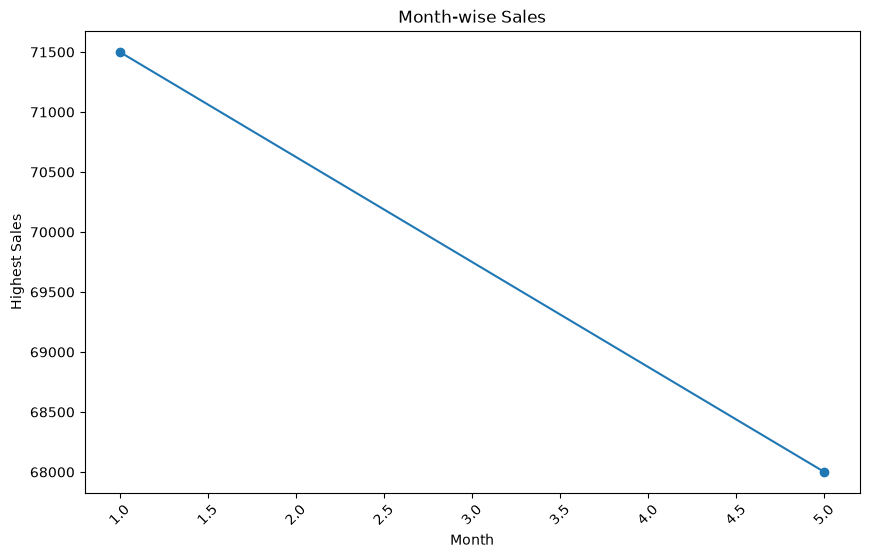

In [23]:
month_sales = df.groupby("month_number")["highest_sales"].sum()

plt.figure(figsize=(10, 6))

plt.plot(month_sales.index, month_sales.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Highest Sales")
plt.title("Month-wise Sales")

plt.xticks(rotation=45)
plt.show()

In [24]:
#Find the top 3 customers in each city.
query='select city,max(quantity * price) as highest_total from orders o join cust c on o.customer_id=c.customer_id group by city order by highest_total  desc limit 3'
df=pd.read_sql(query,connection)
print(df)


     city  highest_total
0    Pune        55000.0
1  Mumbai        30000.0
2  Nashik        28000.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\109944488.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


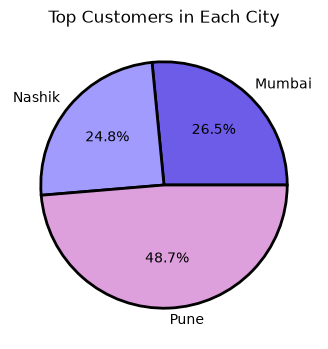

In [25]:
plt.figure(figsize=(6, 4))

top_three_cust_city = df.groupby('city')['highest_total'].max()

plt.pie(
    top_three_cust_city.values,
    labels=top_three_cust_city.index,
    colors=['#6C5CE7', '#A29BFE', '#DDA0DD', '#E0BBE4'],
    autopct='%1.1f%%',
    wedgeprops={'edgecolor': 'black', 'linewidth': 2}
)

plt.title('Top Customers in Each City')

plt.show()


In [26]:
#line chart 
#How does the total revenue change month by month?
query="select month(signup_date) as month_number ,sum(quantity * price) as total_revenue from orders o inner join cust c on o.customer_id=c.customer_id group by month(signup_date) having total_revenue ;"
df=pd.read_sql(query,connection)
print(df)


   month_number  total_revenue
0             1        71500.0
1             2        57000.0
2             3        38400.0
3             4        18000.0
4             5        68000.0
5             6        12800.0
6             7        34500.0
7             8        10000.0
8             9         7400.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_9060\2678641534.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql(query,connection)


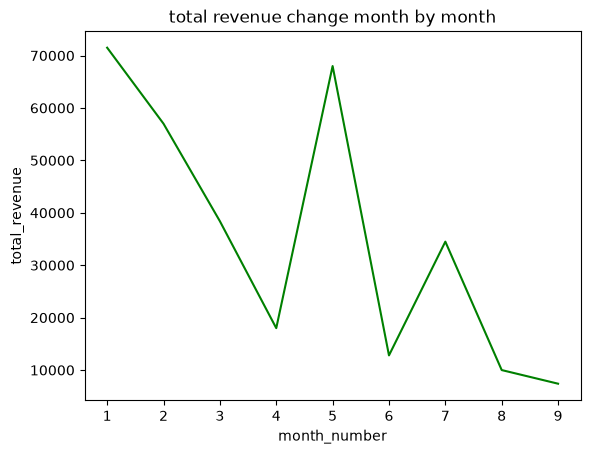

In [27]:
totol_revenue_month=df.groupby('month_number')['total_revenue'].sum()
plt.plot(totol_revenue_month.index,totol_revenue_month.values,color='green')
plt.xlabel('month_number')
plt.ylabel('total_revenue')
plt.title('total revenue change month by month')
plt.show()

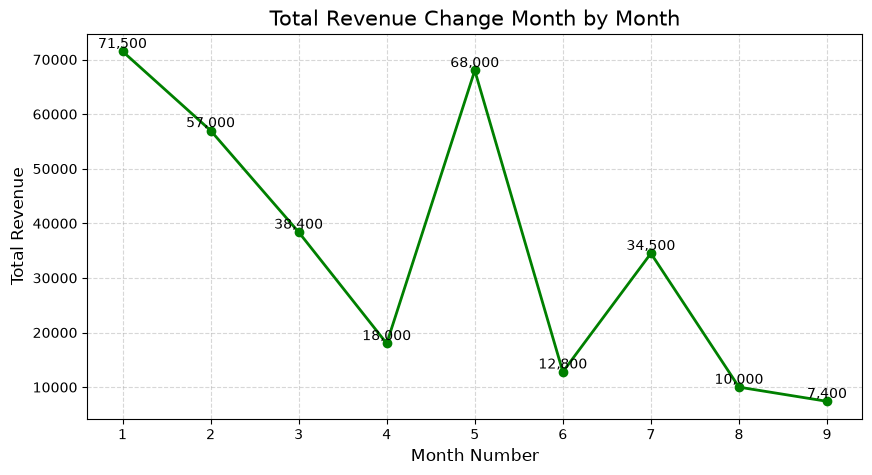

In [28]:
total_revenue_month = df.groupby('month_number')['total_revenue'].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    total_revenue_month.index,
    total_revenue_month.values,
    color='green',
    marker='o',
    linewidth=2
)

# in every points see the revenue
for x, y in zip(total_revenue_month.index, total_revenue_month.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Month Number', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.title('Total Revenue Change Month by Month', fontsize=15)

plt.xticks(total_revenue_month.index)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()